# What sits below the water line on Adelaide's coast?

Port Adelaide, the LeFevre Peninsula, West Lakes, Semaphore and Glenelg sit low. This notebook reads the counts of
land, addresses and residents on ground below a level of still water that the sea could reach, at levels from
published tides and the SA Coast Protection Board's allowances for sea level rise, and then works out one level itself
from the heights so the method can be checked.

**A height-based picture, not a flood or coastal model.** It leaves out tides rising and falling, storm surge, waves,
erosion, sea walls and levees the heights do not show, and drainage. The heights are Geoscience Australia's 5 m LiDAR
DEM (surveys 2001 to 2015, metres AHD, about ±0.3 m at best) through Plotlay's terrain tiles. An address is not a
person or a building.

This notebook reads only `../data`. `../scripts/rebuild_levels.py` rebuilds every count from the heights, the mesh
blocks and G-NAF.

In [1]:
import json, heapq
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tifffile
DATA = '../data'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
lv = pd.read_csv(f'{DATA}/tables/levels.csv')
src = pd.read_csv(f'{DATA}/tables/sources.csv')
summary = json.load(open(f'{DATA}/tables/summary.json'))
g = lv[lv.kind == 'grounded']
print(summary['note'])
g[['level_m_ahd', 'label', 'land_ha', 'residential_addresses', 'addresses', 'residents_2021']]

A height-based picture, not a flood or coastal model. It shows ground below a level of still water and leaves out tides, storm surge, waves, erosion, sea walls and levees the heights do not show, and drainage. How close it is depends on the height data. Heights: Plotlay’s terrain tiles: in Australia Geoscience Australia’s 5 m LiDAR DEM (bare earth, surveys from 2001 to 2015) via Mapterhorn, which keeps its heights as they are, in metres AHD (Australian Height Datum); vertical accuracy about ±0.3 m at best: Geoscience Australia gives the LiDAR capture standard (at least 0.30 m, 95% confidence) rather than a measured accuracy for its 5 m DEM, and the tiles round heights to 0.125 m.


,level_m_ahd,label,land_ha,residential_addresses,addresses,residents_2021
0,1.4,Highest tide today,2057,134,1038,227
1,1.7,Highest tide + 0.3 m,2233,158,1181,256
2,2.4,Highest tide + 1.0 m,4106,12698,15201,23206
3,2.7,1-in-100-year storm tide + 0.3 m,4927,19066,22169,34984
4,3.4,1-in-100-year storm tide + 1.0 m,7607,34993,40540,63027


## 1. The grounded levels and where they come from

In [2]:
pd.set_option('display.max_colwidth', 120)
src[['level_m_ahd', 'label', 'how']]

,level_m_ahd,label,how
0,1.4,Highest tide today,"Highest astronomical tide at Outer Harbor: 2.847 m above the port's chart datum (lowest astronomical tide), which is..."
1,1.7,Highest tide + 0.3 m,The highest tide plus the Coast Protection Board's 0.3 m allowance for sea level rise to 2050
2,2.4,Highest tide + 1.0 m,The highest tide plus the Board's 1.0 m allowance to 2100
3,2.7,1-in-100-year storm tide + 0.3 m,"The 1% AEP (1-in-100-year) still water storm tide for the metropolitan coast, 2.4 m AHD, plus 0.3 m: the basis of th..."
4,3.4,1-in-100-year storm tide + 1.0 m,The same storm tide plus the Board's 1.0 m to 2100


## 2. Below each level

Connected to the sea, the count barely moves from the highest tide (1.4 m AHD) to 1.7 m, then climbs once the water
can pass the dunes and banks into the low suburbs behind them.

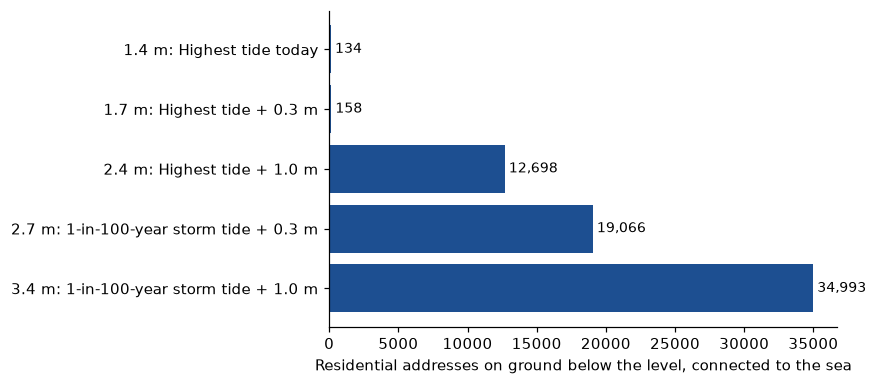

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh([f"{r.level_m_ahd:.1f} m: {r.label}" for r in g.itertuples()][::-1], g.residential_addresses[::-1], color='#1d4f91')
for y, v in enumerate(g.residential_addresses[::-1]): ax.text(v, y, f' {v:,}', va='center', fontsize=9)
ax.set_xlabel('Residential addresses on ground below the level, connected to the sea')
plt.tight_layout(); plt.show()

## 3. Connected to the sea, or every low spot

Everything below the level counts far more at the low levels, because low ground behind higher ground fills too.

In [4]:
b = pd.DataFrame(summary['bathtub_comparison'])
cmp = g[['level_m_ahd', 'residential_addresses']].merge(b.rename(columns={'level': 'level_m_ahd', 'residential': 'everything_below'}), on='level_m_ahd')
cmp.rename(columns={'residential_addresses': 'connected_to_the_sea'})[['level_m_ahd', 'connected_to_the_sea', 'everything_below']]

,level_m_ahd,connected_to_the_sea,everything_below
0,1.4,134,1173
1,1.7,158,2726
2,2.4,12698,15909
3,2.7,19066,20721
4,3.4,34993,35652


## 4. Suburb by suburb

In [5]:
s = pd.read_csv(f'{DATA}/tables/suburbs.csv', dtype={'sal_code': str})
assert s.under_2_4m_ahd.sum() == int(g[g.level_m_ahd == 2.4].residential_addresses.iloc[0]), 'the suburbs add up to the total'
s.sort_values('under_2_4m_ahd', ascending=False).head(12)[['suburb', 'residential_addresses', 'under_1_4m_ahd', 'under_2_4m_ahd', 'under_3_4m_ahd']]

,suburb,residential_addresses,under_1_4m_ahd,under_2_4m_ahd,under_3_4m_ahd
76,West Lakes,3777,0,2893,3749
79,Semaphore Park,2543,0,1498,2218
71,Grange (SA),3333,0,1478,2842
78,West Lakes Shore,1665,0,1218,1318
84,Rosewater,2004,0,954,1960
94,Ethelton,898,0,822,898
5,Ottoway,1351,0,786,1351
88,Port Adelaide,1224,0,779,1194
86,Glanville,461,0,458,461
82,Queenstown (SA),1264,0,389,1065


## 5. Illustration only: 0 to 10 m

The shape of the land, not a forecast.

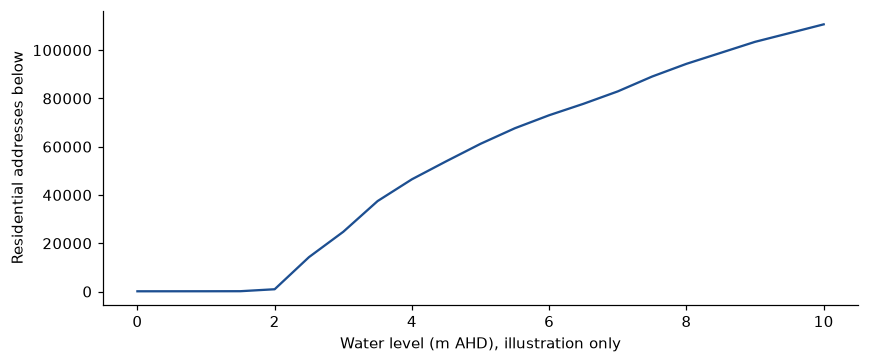

In [6]:
run = lv[lv.kind == 'illustration']
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(run.level_m_ahd, run.residential_addresses, color='#1d4f91')
ax.set_xlabel('Water level (m AHD), illustration only'); ax.set_ylabel('Residential addresses below')
plt.tight_layout(); plt.show()

## 6. A water level of our own

The method on the 8 m heights around Port Adelaide and West Lakes, in plain Python: water starts at the cells on the
grid's edges at or below 0 m AHD (the sea), spreads to the 8 cells around each cell, and each cell gets the lowest
water level that reaches it (a priority flood). Everything below 2.4 m that the sea can reach is then one comparison.

1,994 ha of land below 2.4 m AHD connected to the sea; 2,218 ha below it counting every low spot


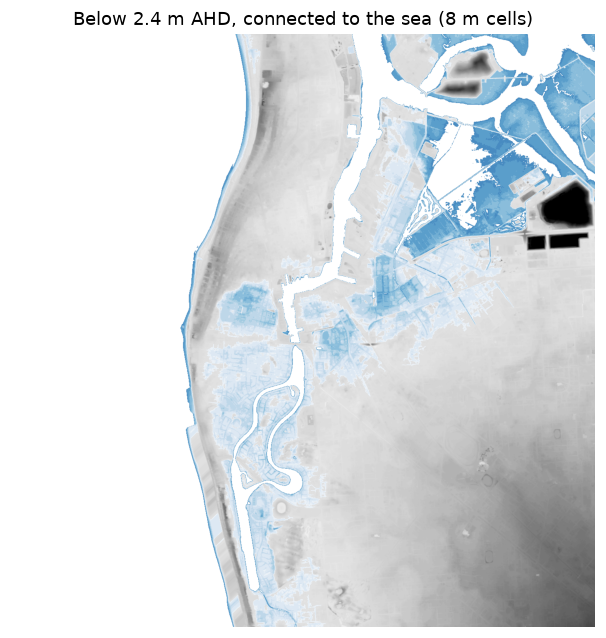

In [7]:
with tifffile.TiffFile(f'{DATA}/heights/ground_height_8m_ahd.tif') as t:
    z = t.pages[0].asarray().astype(float)
    sx, sy = t.pages[0].tags['ModelPixelScaleTag'].value[:2]; x0, y0 = t.pages[0].tags['ModelTiepointTag'].value[3:5]
R = 6378137
lat = np.degrees(2 * np.arctan(np.exp((y0 - (np.arange(z.shape[0]) + 0.5) * sy) / R)) - np.pi / 2)
lng = np.degrees((x0 + (np.arange(z.shape[1]) + 0.5) * sx) / R)
rows = np.where((lat <= -34.80) & (lat >= -34.90))[0]; cols = np.where(lng <= 138.56)[0]
zz = z[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]; H, W = zz.shape
fill = np.full(H * W, np.inf); done = np.zeros(H * W, bool); zf = zz.ravel(); heap = []
for r in range(H):
    for c in range(W):
        if (r in (0, H - 1) or c in (0, W - 1)) and zf[r * W + c] <= 0:
            i = r * W + c; done[i] = True; fill[i] = zf[i]; heap.append((zf[i], i))
heapq.heapify(heap)
while heap:
    k, i = heapq.heappop(heap); r, c = divmod(i, W)
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            rr, cc = r + dr, c + dc
            if (dr or dc) and 0 <= rr < H and 0 <= cc < W and not done[rr * W + cc]:
                j = rr * W + cc; done[j] = True; fill[j] = max(zf[j], k); heapq.heappush(heap, (fill[j], j))
fill = fill.reshape(H, W)
area = (sx * sy * np.cos(np.radians(lat[rows]))[:, None] ** 2)
wet = (fill <= 2.4) & (zz > 0); tub = (zz <= 2.4) & (zz > 0)
print(f'{(area * wet).sum() / 1e4:,.0f} ha of land below 2.4 m AHD connected to the sea; {(area * tub).sum() / 1e4:,.0f} ha below it counting every low spot')
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(np.where(zz > 0, zz, np.nan), cmap='Greys', vmin=-2, vmax=20)
ax.imshow(np.where(wet, 2.4 - zz, np.nan), cmap='Blues', vmin=0, vmax=3, alpha=0.85)
ax.set_title('Below 2.4 m AHD, connected to the sea (8 m cells)'); ax.axis('off'); plt.show()

## What the heights can and cannot tell

- The LiDAR surveys date from 2001 to 2015: ground raised since (New Port, parts of North Haven) shows at its old
  height, and address points on marina berths sit on cells the survey reads as water.
- West Lakes joins the sea through regulated gates, which the model lets water through; narrow sea walls and levees
  can be missed.
- On 8 m cells the counts at 2.4 to 3.4 m are lower than on 4 m cells, because narrow low paths are lost.
- Not advice about any property.